# Predikcija posljedica saobraćajnih nezgoda 

In [27]:
# 1. Uvoz biblioteka

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

from imblearn.over_sampling import SMOTENC         
from imblearn.pipeline import Pipeline as ImbPipeline  

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from catboost import CatBoostClassifier   # koristimo ga na kraju kao opcioni bonus model

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    make_scorer,
)


## FAZA 1 — Učitavanje podataka

In [28]:
PUTANJA_DO_PODATAKA = "../data/nez-opendata-2025-20260125.xlsx"

kolone = [
    "ID",
    "Policijska_uprava",
    "Opstina",
    "Datum_vrijeme",
    "Longitude",
    "Latitude",
    "Posljedica",
    "Tip_nezgode",
    "Opis_nezgode"
]

df = pd.read_excel(PUTANJA_DO_PODATAKA, header=None)
df.columns = kolone

df.head()

,ID,Policijska_uprava,Opstina,Datum_vrijeme,Longitude,Latitude,Posljedica,Tip_nezgode,Opis_nezgode
0,1510533,BEOGRAD,BARAJEVO,"05.01.2025,18:50",20.366175,44.619215,Sa mat.stetom,SN SA PARKIRANIM VOZILIMA,Ostali sudari sa parkiranim vozilom
1,1508366,BEOGRAD,BARAJEVO,"06.01.2025,01:00",20.351757,44.604264,Sa mat.stetom,SN SA PARKIRANIM VOZILIMA,Sudar sa parkiranim vozilom sa leve strane kol...
2,1510854,BEOGRAD,BARAJEVO,"06.01.2025,16:30",20.342381,44.588294,Sa povredjenim,SN SA NAJMANjE DVA VOZILA – SKRETANjE ILI PREL...,Najmanje dva vozila koja se kreću istim putem ...
3,1511079,BEOGRAD,BARAJEVO,"09.01.2025,13:05",20.366297,44.618967,Sa mat.stetom,SN SA NAJMANjE DVA VOZILA – SKRETANjE ILI PREL...,Najmanje dva vozila koja se kreću istim putem ...
4,1508796,BEOGRAD,BARAJEVO,"11.01.2025,02:30",20.413140,44.607341,Sa mat.stetom,SN SA JEDNIM VOZILOM,Nezgode sa učešćem jednog vozila i životinja


In [29]:
df.shape

(33415, 9)

In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33415 entries, 0 to 33414
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ID                 33415 non-null  int64  
 1   Policijska_uprava  33415 non-null  object 
 2   Opstina            33415 non-null  object 
 3   Datum_vrijeme      33415 non-null  object 
 4   Longitude          33415 non-null  float64
 5   Latitude           33415 non-null  float64
 6   Posljedica         33415 non-null  object 
 7   Tip_nezgode        33415 non-null  object 
 8   Opis_nezgode       33415 non-null  object 
dtypes: float64(2), int64(1), object(6)
memory usage: 2.3+ MB


## FAZA 2 — Provjera kvaliteta podataka

In [31]:
df.isnull().sum()

ID                   0
Policijska_uprava    0
Opstina              0
Datum_vrijeme        0
Longitude            0
Latitude             0
Posljedica           0
Tip_nezgode          0
Opis_nezgode         0
dtype: int64

In [32]:
df.duplicated().sum()

np.int64(2)

In [33]:
# Numerički atributi

df[["Longitude", "Latitude"]].describe()

,Longitude,Latitude
count,33415.000000,33415.000000
mean,20.518304,44.560683
std,0.681428,0.695698
min,18.824317,41.871823
25%,20.154623,44.261215
50%,20.454207,44.776650
75%,20.680062,44.845631
max,22.832379,46.174400


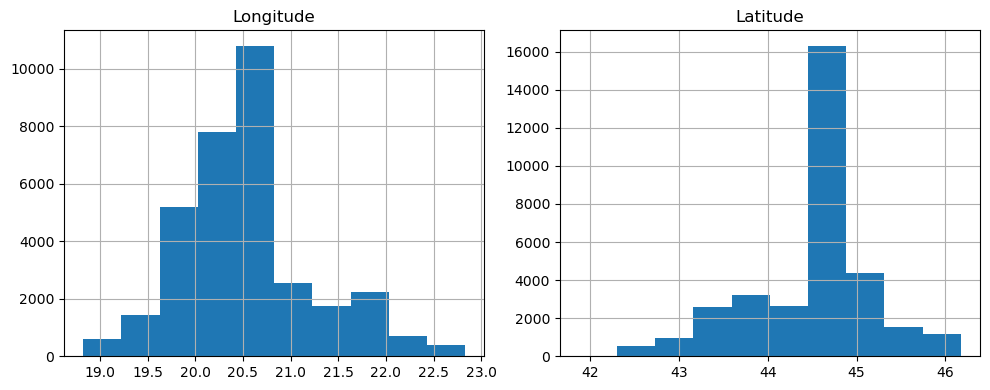

In [34]:
df[["Longitude", "Latitude"]].hist(figsize=(10, 4))
plt.tight_layout()
plt.show()

## FAZA 3 — Analiza ciljne promjenljive i kategorijskih atributa

In [35]:
df["Posljedica"].value_counts()

Posljedica
Sa mat.stetom     19819
Sa povredjenim    13133
Sa poginulim        463
Name: count, dtype: int64

In [36]:
df["Posljedica"].value_counts(normalize=True)

Posljedica
Sa mat.stetom     0.593117
Sa povredjenim    0.393027
Sa poginulim      0.013856
Name: proportion, dtype: float64

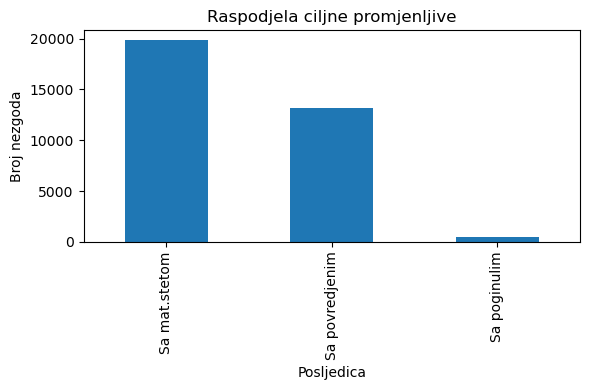

In [37]:
plt.figure(figsize=(6, 4))
df["Posljedica"].value_counts().plot(kind="bar")
plt.title("Raspodjela ciljne promjenljive")
plt.xlabel("Posljedica")
plt.ylabel("Broj nezgoda")
plt.tight_layout()
plt.show()

# Napomena: klasa "Sa poginulim" je znatno manje zastupljena od ostale dvije — ovo je razlog
# zašto je balansiranje klasa (SMOTENC) i praćenje recall-a po klasi (a ne samo accuracy) bitno.

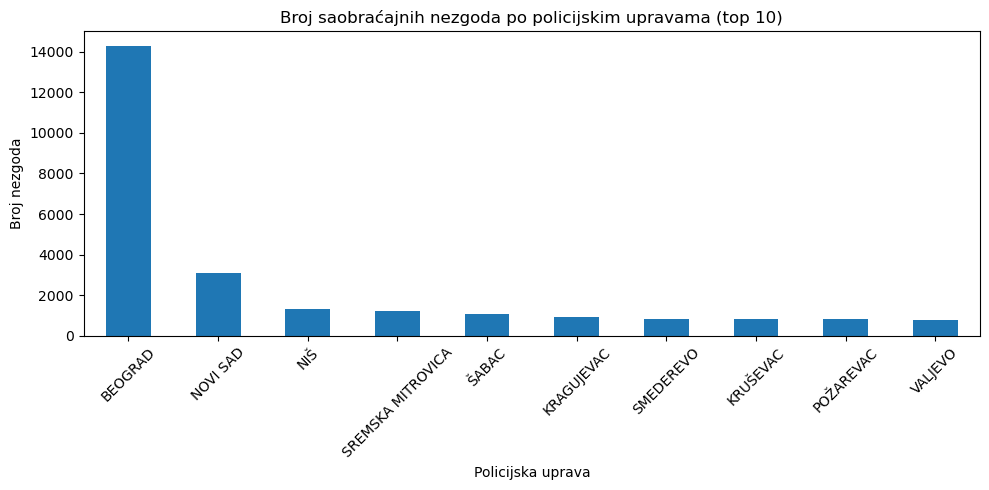

In [38]:
plt.figure(figsize=(10, 5))
df["Policijska_uprava"].value_counts().head(10).plot(kind="bar")
plt.title("Broj saobraćajnih nezgoda po policijskim upravama (top 10)")
plt.xlabel("Policijska uprava")
plt.ylabel("Broj nezgoda")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

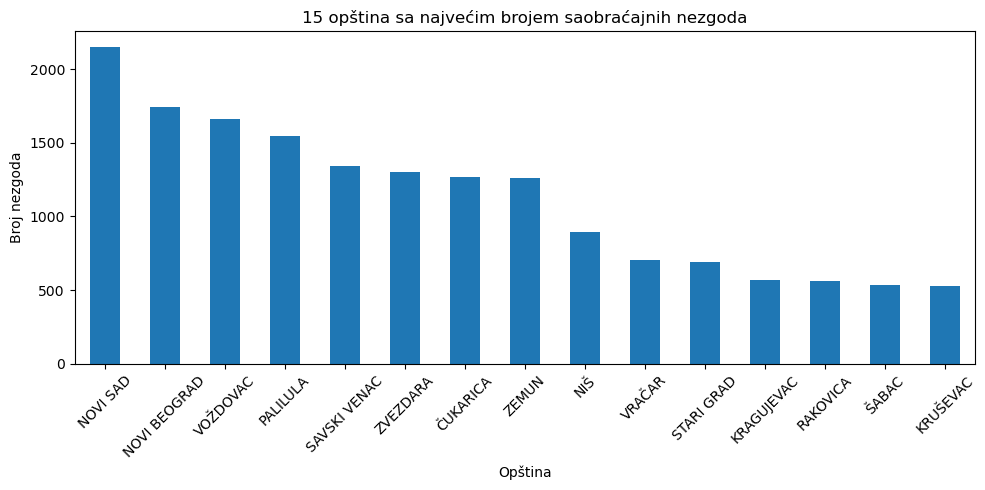

In [39]:
top_opstine = df["Opstina"].value_counts().head(15)

plt.figure(figsize=(10, 5))
top_opstine.plot(kind="bar")
plt.title("15 opština sa najvećim brojem saobraćajnih nezgoda")
plt.xlabel("Opština")
plt.ylabel("Broj nezgoda")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

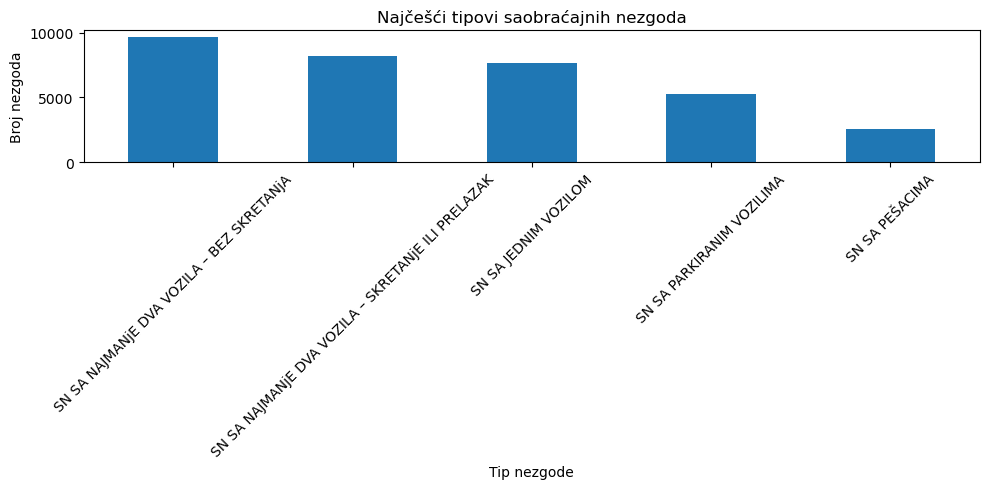

In [40]:
top_tipovi = df["Tip_nezgode"].value_counts().head(15)

plt.figure(figsize=(10, 5))
top_tipovi.plot(kind="bar")
plt.title("Najčešći tipovi saobraćajnih nezgoda")
plt.xlabel("Tip nezgode")
plt.ylabel("Broj nezgoda")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Posljedica                                          Sa mat.stetom  \
Tip_nezgode                                                         
SN SA JEDNIM VOZILOM                                        63.74   
SN SA NAJMANjE DVA VOZILA – BEZ SKRETANjA                   59.20   
SN SA NAJMANjE DVA VOZILA – SKRETANjE ILI PRELAZAK          52.11   
SN SA PARKIRANIM VOZILIMA                                   92.68   
SN SA PEŠACIMA                                               1.55   

Posljedica                                          Sa povredjenim  \
Tip_nezgode                                                          
SN SA JEDNIM VOZILOM                                         34.33   
SN SA NAJMANjE DVA VOZILA – BEZ SKRETANjA                    39.45   
SN SA NAJMANjE DVA VOZILA – SKRETANjE ILI PRELAZAK           46.99   
SN SA PARKIRANIM VOZILIMA                                     7.21   
SN SA PEŠACIMA                                               94.41   

Posljedica               

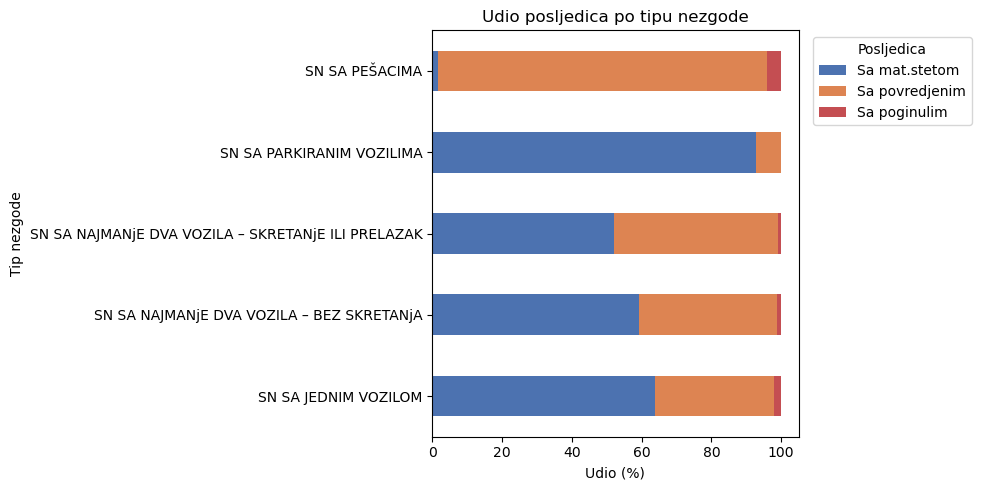

In [41]:
# Crosstab: Tip_nezgode x Posljedica - udio posljedica po tipu nezgode
ct_tip = pd.crosstab(df["Tip_nezgode"], df["Posljedica"], normalize="index") * 100
ct_tip = ct_tip[["Sa mat.stetom", "Sa povredjenim", "Sa poginulim"]]
print(ct_tip.round(2))

ct_tip.plot(kind="barh", stacked=True, figsize=(10, 5), color=["#4C72B0", "#DD8452", "#C44E52"])
plt.xlabel("Udio (%)")
plt.ylabel("Tip nezgode")
plt.title("Udio posljedica po tipu nezgode")
plt.legend(title="Posljedica", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Napomena: nezgode sa pješacima gotovo nikad ne završavaju samo materijalnom štetom (1,6%),
# za razliku od nezgoda sa parkiranim vozilima gdje je to dominantan ishod (92,7%).

In [42]:
for col in ["Policijska_uprava", "Opstina", "Tip_nezgode", "Opis_nezgode"]:
    print(f"{col}: {df[col].nunique()} jedinstvenih vrijednosti")

Policijska_uprava: 27 jedinstvenih vrijednosti
Opstina: 162 jedinstvenih vrijednosti
Tip_nezgode: 5 jedinstvenih vrijednosti
Opis_nezgode: 68 jedinstvenih vrijednosti


## FAZA 4 — Obrada datuma

In [43]:
df["Datum_vrijeme"] = pd.to_datetime(
    df["Datum_vrijeme"],
    format="%d.%m.%Y,%H:%M",
    errors="coerce"
)

broj_neparsiranih = df["Datum_vrijeme"].isna().sum()
print(f"Broj redova gdje datum nije uspješno parsiran: {broj_neparsiranih}")

Broj redova gdje datum nije uspješno parsiran: 0


In [44]:
df["Godina"] = df["Datum_vrijeme"].dt.year
df["Mjesec"] = df["Datum_vrijeme"].dt.month
df["Dan"] = df["Datum_vrijeme"].dt.day
df["Sat"] = df["Datum_vrijeme"].dt.hour
df["Dan_u_sedmici"] = df["Datum_vrijeme"].dt.day_name()

df[["Datum_vrijeme", "Godina", "Mjesec", "Dan", "Sat", "Dan_u_sedmici"]].head()

,Datum_vrijeme,Godina,Mjesec,Dan,Sat,Dan_u_sedmici
0,2025-01-05 18:50:00,2025,1,5,18,Sunday
1,2025-01-06 01:00:00,2025,1,6,1,Monday
2,2025-01-06 16:30:00,2025,1,6,16,Monday
3,2025-01-09 13:05:00,2025,1,9,13,Thursday
4,2025-01-11 02:30:00,2025,1,11,2,Saturday


### Ciklična (sinusno-kosinusna) transformacija mjeseca i sata

Atributi `Mjesec` (1-12) i `Sat` (0-23) su ciklične promjenljive - decembar (12) je vremenski blizak januaru (1) isto koliko i novembru (11), a 23. sat je blizak 0. satu isto koliko i 22. satu. Ako se ovi atributi ostave u izvornom, linearnom obliku, model ih tretira kao da su 1 i 12 (odnosno 0 i 23) maksimalno udaljene vrijednosti, što ne odgovara stvarnosti i unosi lažnu, nepostojeću linearnost u podatke.

Radi ispravnog predstavljanja cikličnosti, svaka od ove dvije promjenljive transformisana je u dvije nove promjenljive pomoću sinusne i kosinusne funkcije. Ovakvim preslikavanjem, susjedne vrijednosti (npr. sat 23 i sat 0) ostaju bliske i u novom, transformisanom prostoru, čime se otklanja nepostojeća linearnost.

In [45]:
# Ciklicna (sinusno-kosinusna) transformacija Mjeseca i Sata
df["Mjesec_sin"] = np.sin(2 * np.pi * df["Mjesec"] / 12)
df["Mjesec_cos"] = np.cos(2 * np.pi * df["Mjesec"] / 12)
df["Sat_sin"] = np.sin(2 * np.pi * df["Sat"] / 24)
df["Sat_cos"] = np.cos(2 * np.pi * df["Sat"] / 24)

df[["Mjesec", "Mjesec_sin", "Mjesec_cos", "Sat", "Sat_sin", "Sat_cos"]].head()

,Mjesec,Mjesec_sin,Mjesec_cos,Sat,Sat_sin,Sat_cos
0,1,0.5,0.866025,18,-1.000000,-1.836970e-16
1,1,0.5,0.866025,1,0.258819,9.659258e-01
2,1,0.5,0.866025,16,-0.866025,-5.000000e-01
3,1,0.5,0.866025,13,-0.258819,-9.659258e-01
4,1,0.5,0.866025,2,0.500000,8.660254e-01


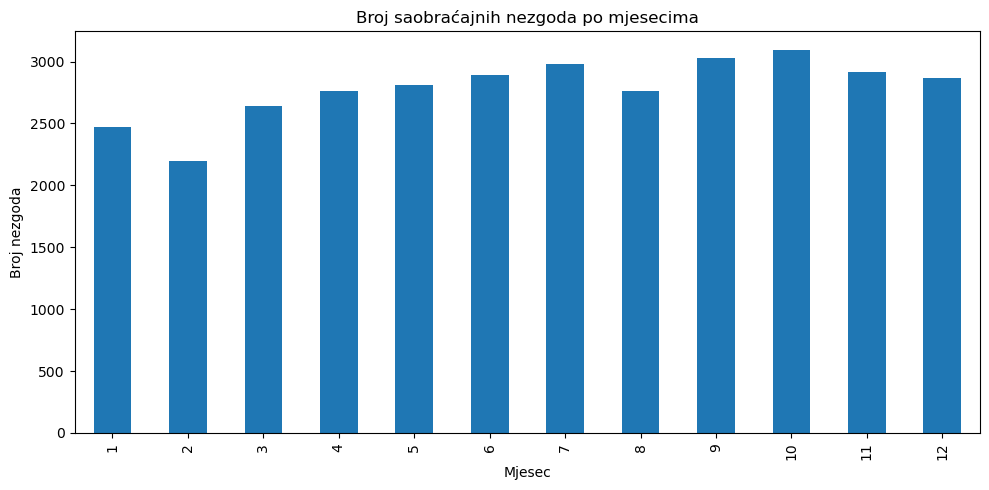

In [46]:
plt.figure(figsize=(10, 5))
df["Mjesec"].value_counts().sort_index().plot(kind="bar")
plt.title("Broj saobraćajnih nezgoda po mjesecima")
plt.xlabel("Mjesec")
plt.ylabel("Broj nezgoda")
plt.tight_layout()
plt.show()

        Materijalna šteta  Povrijeđeni  Poginuli
Mjesec                                          
1                    1513          925        33
2                    1398          772        25
3                    1607          996        36
4                    1691         1036        34
5                    1660         1112        39
6                    1595         1244        50
7                    1717         1229        32
8                    1477         1245        44
9                    1672         1303        55
10                   1826         1222        42
11                   1784         1091        42
12                   1879          958        31


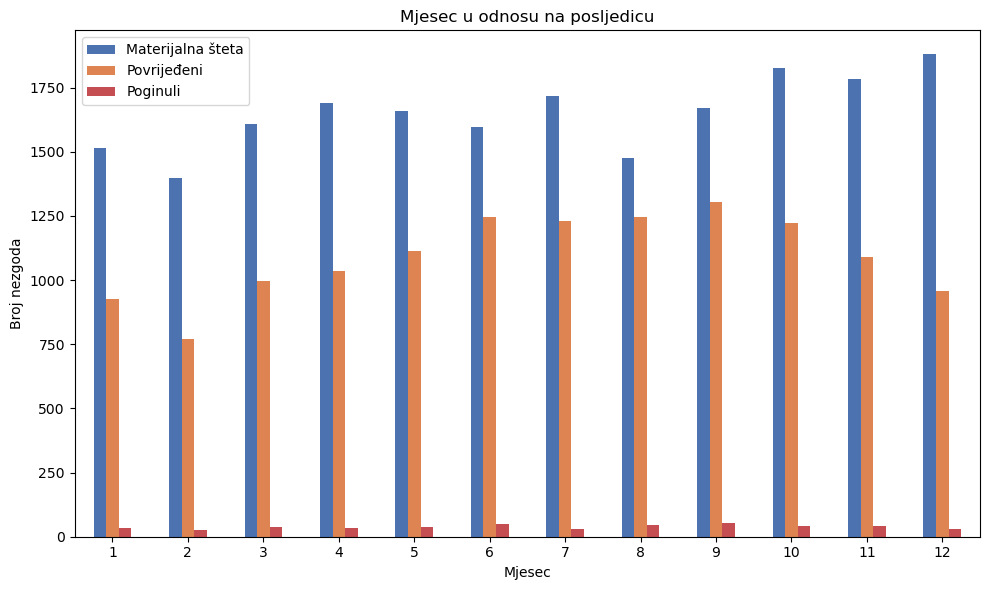


Udio poginulih po mjesecu (%):
Mjesec
9     1.82
6     1.73
8     1.59
11    1.44
5     1.39
10    1.36
3     1.36
1     1.34
4     1.23
2     1.14
12    1.08
7     1.07
Name: Sa poginulim, dtype: float64


In [47]:
# Crosstab: Mjesec x Posljedica
ct_mjesec = pd.crosstab(df["Mjesec"], df["Posljedica"])
ct_mjesec = ct_mjesec[["Sa mat.stetom", "Sa povredjenim", "Sa poginulim"]]
ct_mjesec.columns = ["Materijalna šteta", "Povrijeđeni", "Poginuli"]
print(ct_mjesec)

ct_mjesec.plot(kind="bar", figsize=(10, 6), color=["#4C72B0", "#DD8452", "#C44E52"])
plt.title("Mjesec u odnosu na posljedicu")
plt.xlabel("Mjesec")
plt.ylabel("Broj nezgoda")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

udio_mjesec = pd.crosstab(df["Mjesec"], df["Posljedica"], normalize="index")["Sa poginulim"] * 100
print("\nUdio poginulih po mjesecu (%):")
print(udio_mjesec.round(2).sort_values(ascending=False))

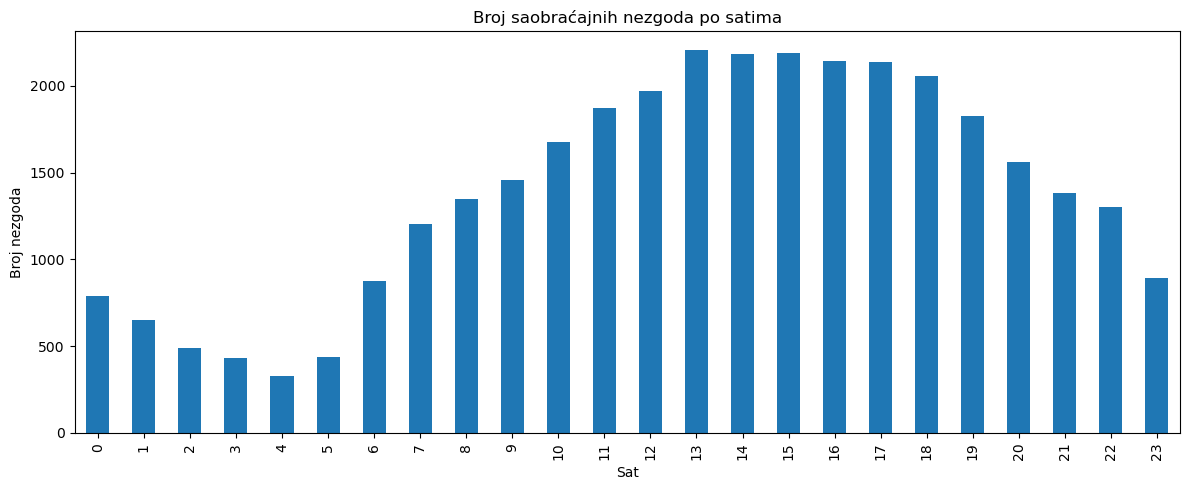

In [48]:
plt.figure(figsize=(12, 5))
df["Sat"].value_counts().sort_index().plot(kind="bar")
plt.title("Broj saobraćajnih nezgoda po satima")
plt.xlabel("Sat")
plt.ylabel("Broj nezgoda")
plt.tight_layout()
plt.show()

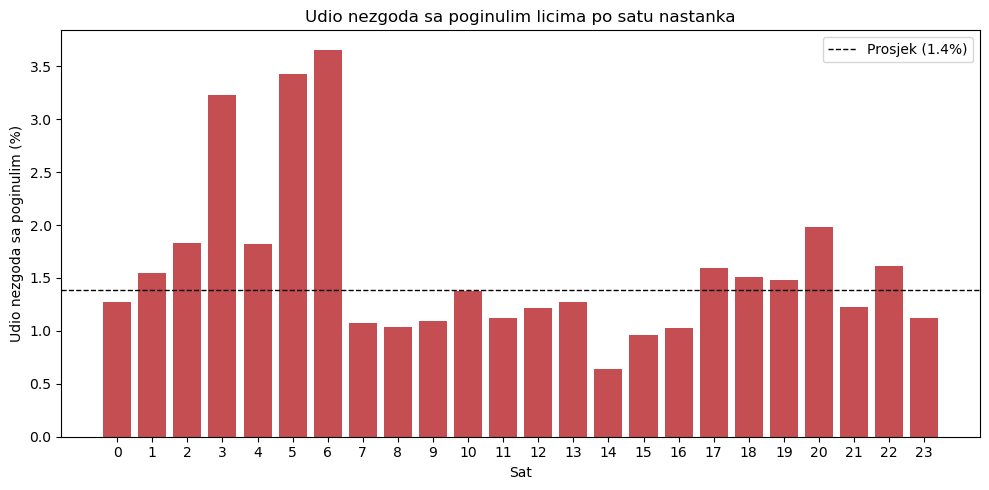

Sat
6     3.66
5     3.42
3     3.23
20    1.98
2     1.83
4     1.82
Name: Sa poginulim, dtype: float64


In [49]:
# Crosstab: Sat x Posljedica - udio poginulih po satu nastanka
ct_sat = pd.crosstab(df["Sat"], df["Posljedica"], normalize="index") * 100
prosjek_poginulih = df["Posljedica"].eq("Sa poginulim").mean() * 100

plt.figure(figsize=(10, 5))
plt.bar(ct_sat.index, ct_sat["Sa poginulim"], color="#C44E52")
plt.axhline(y=prosjek_poginulih, color="black", linestyle="--", linewidth=1,
            label=f"Prosjek ({prosjek_poginulih:.1f}%)")
plt.xlabel("Sat")
plt.ylabel("Udio nezgoda sa poginulim (%)")
plt.title("Udio nezgoda sa poginulim licima po satu nastanka")
plt.xticks(range(0, 24))
plt.legend()
plt.tight_layout()
plt.show()

print(ct_sat["Sa poginulim"].round(2).sort_values(ascending=False).head(6))

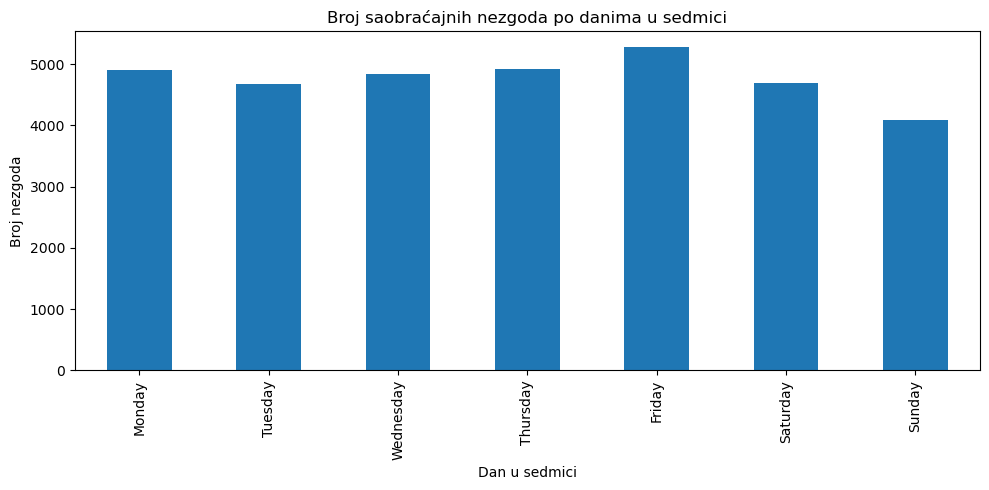

In [50]:
redoslijed = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

df["Dan_u_sedmici"] = pd.Categorical(
    df["Dan_u_sedmici"],
    categories=redoslijed,
    ordered=True
)

plt.figure(figsize=(10, 5))
df["Dan_u_sedmici"].value_counts().sort_index().plot(kind="bar")
plt.title("Broj saobraćajnih nezgoda po danima u sedmici")
plt.xlabel("Dan u sedmici")
plt.ylabel("Broj nezgoda")
plt.tight_layout()
plt.show()

               Materijalna šteta  Povrijeđeni  Poginuli
Dan_u_sedmici                                          
Monday                      2883         1957        69
Tuesday                     2778         1837        60
Wednesday                   2938         1841        68
Thursday                    2938         1920        60
Friday                      3125         2086        63
Saturday                    2741         1891        66
Sunday                      2416         1601        77


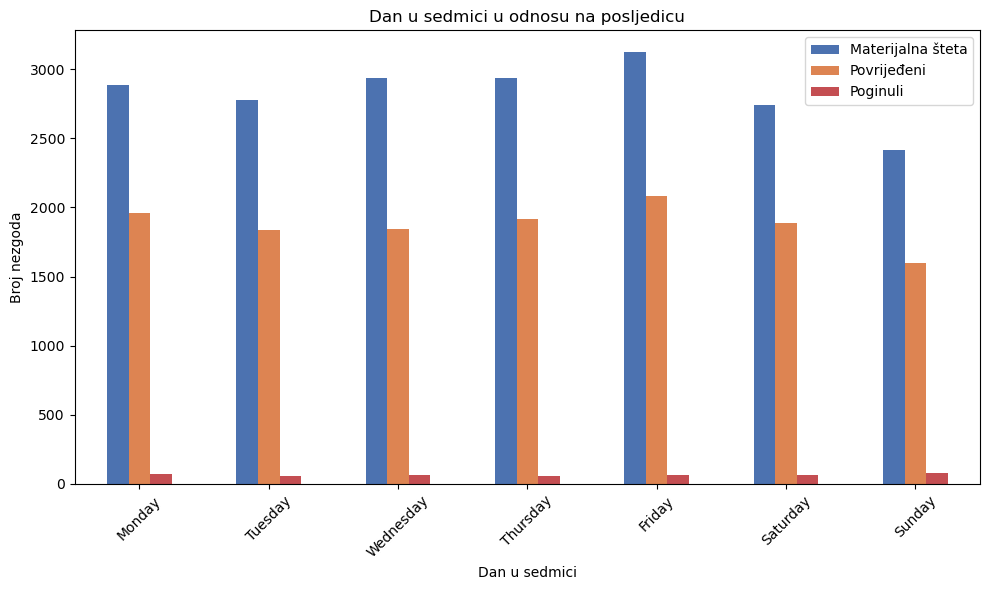


Udio poginulih po danu (%):
Dan_u_sedmici
Monday       1.41
Tuesday      1.28
Wednesday    1.40
Thursday     1.22
Friday       1.19
Saturday     1.40
Sunday       1.88
Name: Sa poginulim, dtype: float64


In [51]:
# Crosstab: Dan_u_sedmici x Posljedica
ct_dan = pd.crosstab(df["Dan_u_sedmici"], df["Posljedica"]).reindex(redoslijed)
ct_dan = ct_dan[["Sa mat.stetom", "Sa povredjenim", "Sa poginulim"]]
ct_dan.columns = ["Materijalna šteta", "Povrijeđeni", "Poginuli"]
print(ct_dan)

ct_dan.plot(kind="bar", figsize=(10, 6), color=["#4C72B0", "#DD8452", "#C44E52"])
plt.title("Dan u sedmici u odnosu na posljedicu")
plt.xlabel("Dan u sedmici")
plt.ylabel("Broj nezgoda")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

udio_dan = pd.crosstab(df["Dan_u_sedmici"], df["Posljedica"], normalize="index").reindex(redoslijed)["Sa poginulim"] * 100
print("\nUdio poginulih po danu (%):")
print(udio_dan.round(2))

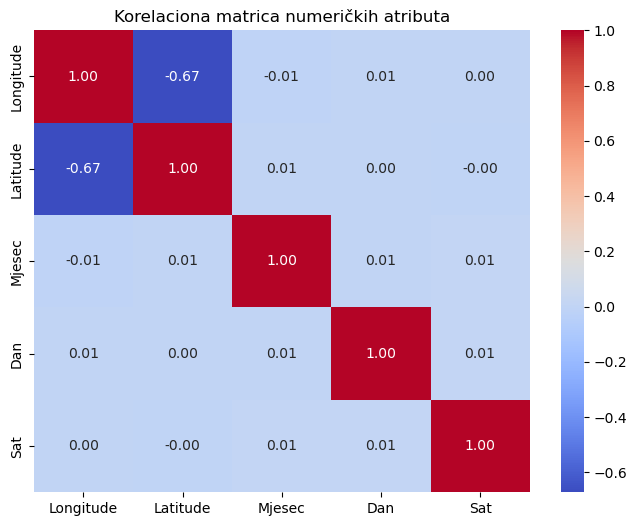

In [52]:
numericki = df[["Longitude", "Latitude", "Mjesec", "Dan", "Sat"]]
korelacija = numericki.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(korelacija, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Korelaciona matrica numeričkih atributa")
plt.show()

## FAZA 5 — Provjera curenja podataka (data leakage) preko `Opis_nezgode`


In [53]:
print("Broj jedinstvenih vrijednosti u Opis_nezgode:", df["Opis_nezgode"].nunique())
print("Broj jedinstvenih vrijednosti u Tip_nezgode:  ", df["Tip_nezgode"].nunique())

kljucna_rijec = "pogin"  # korijen riječi "poginuo/poginula/poginulih" itd.

udio_kod_poginulih = (
    df.loc[df["Posljedica"] == "Sa poginulim", "Opis_nezgode"]
      .str.contains(kljucna_rijec, case=False, na=False)
      .mean()
)

udio_kod_ostalih = (
    df.loc[df["Posljedica"] != "Sa poginulim", "Opis_nezgode"]
      .str.contains(kljucna_rijec, case=False, na=False)
      .mean()
)

print(f"Udio opisa koji sadrže '{kljucna_rijec}' kod klase 'Sa poginulim': {udio_kod_poginulih:.2%}")
print(f"Udio opisa koji sadrže '{kljucna_rijec}' kod ostalih klasa:        {udio_kod_ostalih:.2%}")


Broj jedinstvenih vrijednosti u Opis_nezgode: 68
Broj jedinstvenih vrijednosti u Tip_nezgode:   5
Udio opisa koji sadrže 'pogin' kod klase 'Sa poginulim': 0.00%
Udio opisa koji sadrže 'pogin' kod ostalih klasa:        0.00%


## FAZA 6 — Definisanje ulaznih (X) i izlazne (y) promjenljive


In [54]:
kategorijske_kolone = [
    "Policijska_uprava",
    "Opstina",
    "Tip_nezgode",
    "Opis_nezgode",
    "Dan_u_sedmici"
]

numericke_kolone = [
    "Longitude",
    "Latitude",
    "Mjesec_sin",
    "Mjesec_cos",
    "Sat_sin",
    "Sat_cos"
]

X = df[kategorijske_kolone + numericke_kolone]
y = df["Posljedica"]

print(X.shape, y.shape)

(33415, 11) (33415,)


## FAZA 7 — Train/test podjela (PRIJE enkodiranja i SMOTENC)

Podjela na trening i test skup se radi prije bilo kakvog fitovanja (enkoder, SMOTENC, scaler)

In [55]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print(y_train.value_counts(normalize=True) * 100)

X_train: (26732, 11)
X_test : (6683, 11)
Posljedica
Sa mat.stetom     59.310938
Sa povredjenim    39.301212
Sa poginulim       1.387850
Name: proportion, dtype: float64


## FAZA 8 — Balansiranje klasa pomoću SMOTENC

Koristi se `SMOTENC` umjesto običnog `SMOTE` jer podaci sadrže kategorijske atribute. SMOTENC generiše nove uzorke tako da kategorijskim atributima dodjeljuje stvarne (postojeće) kategorije umjesto necjelobrojnih vrijednosti interpolacije.

In [56]:
indeksi_kategorijskih = [X_train.columns.get_loc(c) for c in kategorijske_kolone]

smote_nc = SMOTENC(categorical_features=indeksi_kategorijskih, random_state=42)

X_train_smote, y_train_smote = smote_nc.fit_resample(X_train, y_train)

print("Prije SMOTENC:")
print(y_train.value_counts())
print("\nPoslije SMOTENC:")
print(y_train_smote.value_counts())

Prije SMOTENC:
Posljedica
Sa mat.stetom     15855
Sa povredjenim    10506
Sa poginulim        371
Name: count, dtype: int64

Poslije SMOTENC:
Posljedica
Sa mat.stetom     15855
Sa povredjenim    15855
Sa poginulim      15855
Name: count, dtype: int64


## FAZA 9 — One-Hot enkodiranje (fitovano samo na trening skupu)

In [57]:
encoder = OneHotEncoder(
    drop=None,
    sparse_output=False,
    handle_unknown="ignore"
)

# Fitujemo encoder samo na originalnom (ne-resampliranom) trening skupu.
encoder.fit(X_train[kategorijske_kolone])


def enkodiraj(df_dio):
    """Primjenjuje već fitovani encoder i vraća numeričke + enkodirane kolone spojene u jedan DataFrame."""
    enkodirane = encoder.transform(df_dio[kategorijske_kolone])
    enkodirane_df = pd.DataFrame(
        enkodirane,
        columns=encoder.get_feature_names_out(kategorijske_kolone),
        index=df_dio.index
    )
    return pd.concat([df_dio[numericke_kolone], enkodirane_df], axis=1)


X_train_enc = enkodiraj(X_train)
X_test_enc = enkodiraj(X_test)
X_train_smote_enc = enkodiraj(X_train_smote)

print("X_train_enc:", X_train_enc.shape)
print("X_test_enc :", X_test_enc.shape)
print("X_train_smote_enc:", X_train_smote_enc.shape)

X_train_enc: (26732, 275)
X_test_enc : (6683, 275)
X_train_smote_enc: (47565, 275)


## FAZA 10 — Skaliranje (samo za logističku regresiju)

In [58]:
scaler = StandardScaler()

X_train_smote_scaled = X_train_smote_enc.copy()
X_test_scaled = X_test_enc.copy()

X_train_smote_scaled[numericke_kolone] = scaler.fit_transform(X_train_smote_enc[numericke_kolone])
X_test_scaled[numericke_kolone] = scaler.transform(X_test_enc[numericke_kolone])

## FAZA 11 — Modeli mašinskog učenja


In [59]:
# --- Logistička regresija ---

log_reg = LogisticRegression(
    C=0.1,
    max_iter=2000,
    random_state=42,
    class_weight="balanced"
)

log_reg.fit(X_train_smote_scaled, y_train_smote)
y_pred_lr = log_reg.predict(X_test_scaled)

accuracy_lr = accuracy_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr, average="weighted")

print(f"Tačnost (Logistička regresija): {accuracy_lr:.4f}")
print(classification_report(y_test, y_pred_lr, zero_division=0))

Tačnost (Logistička regresija): 0.6421
                precision    recall  f1-score   support

 Sa mat.stetom       0.83      0.70      0.76      3964
  Sa poginulim       0.04      0.42      0.07        92
Sa povredjenim       0.64      0.56      0.60      2627

      accuracy                           0.64      6683
     macro avg       0.50      0.56      0.48      6683
  weighted avg       0.74      0.64      0.69      6683



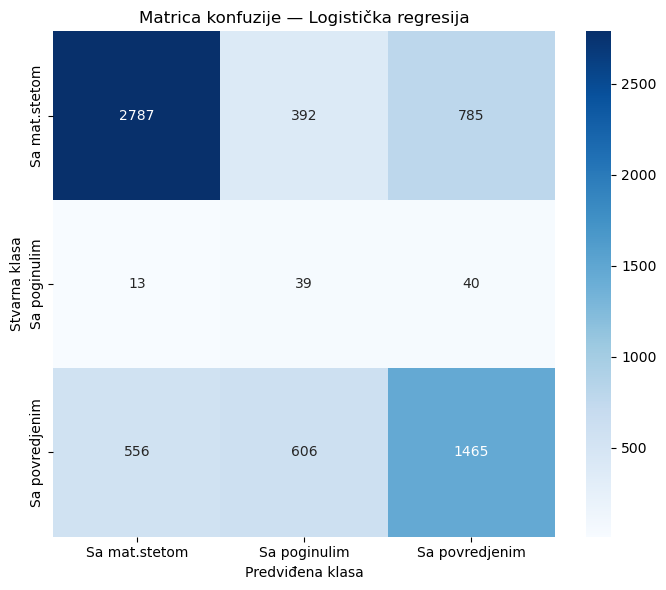

In [60]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm_lr, annot=True, fmt="d", cmap="Blues",
    xticklabels=log_reg.classes_, yticklabels=log_reg.classes_
)
plt.title("Matrica konfuzije — Logistička regresija")
plt.xlabel("Predviđena klasa")
plt.ylabel("Stvarna klasa")
plt.tight_layout()
plt.show()

In [61]:
# --- Decision Tree ---

dt = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=10,
    min_samples_leaf=10,
    min_samples_split=2,
    random_state=42,
    class_weight="balanced"
)

dt.fit(X_train_smote_enc, y_train_smote)
y_pred_dt = dt.predict(X_test_enc)

accuracy_dt = accuracy_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt, average="weighted")

print(f"Tačnost (Decision Tree): {accuracy_dt:.4f}")
print(classification_report(y_test, y_pred_dt, zero_division=0))
print("Train Accuracy:", dt.score(X_train_smote_enc, y_train_smote))
print("Test Accuracy :", dt.score(X_test_enc, y_test))

Tačnost (Decision Tree): 0.6672
                precision    recall  f1-score   support

 Sa mat.stetom       0.83      0.66      0.74      3964
  Sa poginulim       0.03      0.20      0.06        92
Sa povredjenim       0.60      0.70      0.65      2627

      accuracy                           0.67      6683
     macro avg       0.49      0.52      0.48      6683
  weighted avg       0.73      0.67      0.69      6683

Train Accuracy: 0.6776200988121518
Test Accuracy : 0.6672153224599731


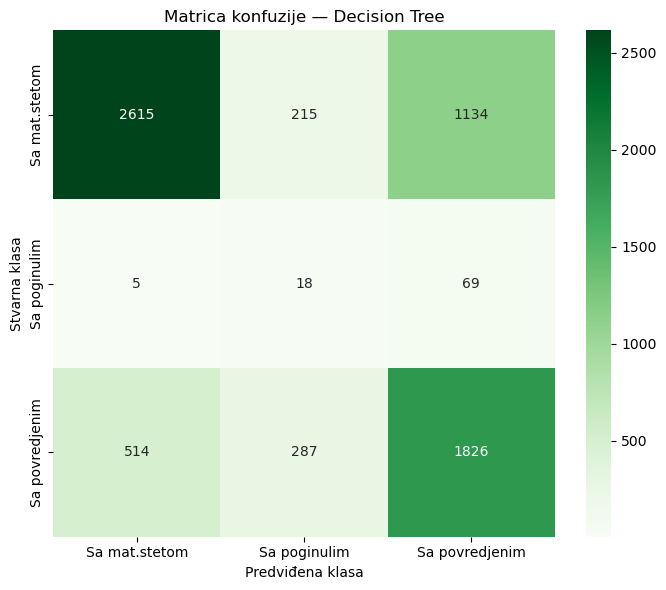

In [62]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm_dt, annot=True, fmt="d", cmap="Greens",
    xticklabels=dt.classes_, yticklabels=dt.classes_
)
plt.title("Matrica konfuzije — Decision Tree")
plt.xlabel("Predviđena klasa")
plt.ylabel("Stvarna klasa")
plt.tight_layout()
plt.show()

In [63]:
# --- Random Forest ---

rf = RandomForestClassifier(
    n_estimators=200,
    criterion="entropy",
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    class_weight="balanced_subsample"  # varijanta "balanced" prilagođena baggingu (bootstrap uzorcima) u RF
)

rf.fit(X_train_smote_enc, y_train_smote)
y_pred_rf = rf.predict(X_test_enc)

accuracy_rf = accuracy_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf, average="weighted")

print(f"Tačnost (Random Forest): {accuracy_rf:.4f}")
print(classification_report(y_test, y_pred_rf, zero_division=0))
print("Train Accuracy:", rf.score(X_train_smote_enc, y_train_smote))
print("Test Accuracy :", rf.score(X_test_enc, y_test))

Tačnost (Random Forest): 0.7262
                precision    recall  f1-score   support

 Sa mat.stetom       0.81      0.75      0.78      3964
  Sa poginulim       0.06      0.11      0.08        92
Sa povredjenim       0.65      0.71      0.68      2627

      accuracy                           0.73      6683
     macro avg       0.51      0.52      0.51      6683
  weighted avg       0.74      0.73      0.73      6683

Train Accuracy: 0.9151056449069694
Test Accuracy : 0.7261708813407153


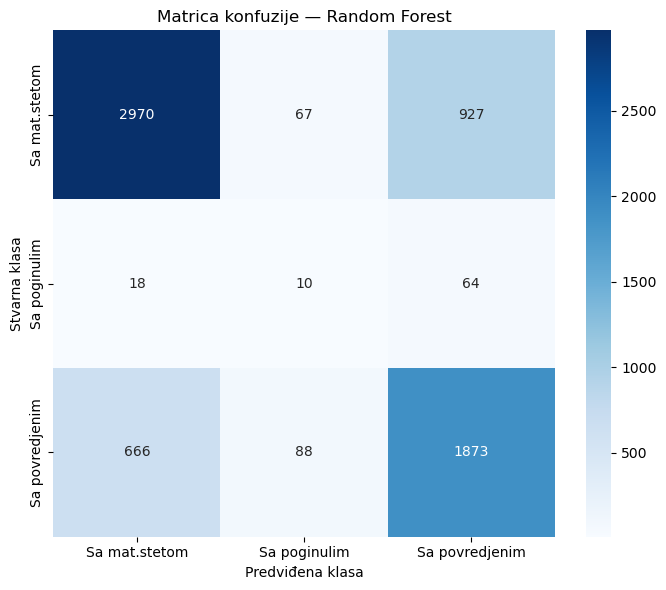

In [64]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm_rf, annot=True, fmt="d", cmap="Blues",
    xticklabels=rf.classes_, yticklabels=rf.classes_
)
plt.title("Matrica konfuzije — Random Forest")
plt.xlabel("Predviđena klasa")
plt.ylabel("Stvarna klasa")
plt.tight_layout()
plt.show()


In [65]:
feature_importance = pd.DataFrame({
    "Atribut": X_train_smote_enc.columns,
    "Važnost": rf.feature_importances_
}).sort_values(by="Važnost", ascending=False)

feature_importance.head(20)

,Atribut,Važnost
1,Latitude,0.073804
0,Longitude,0.067842
5,Sat_cos,0.061793
4,Sat_sin,0.058553
198,Tip_nezgode_SN SA PARKIRANIM VOZILIMA,0.052031
3,Mjesec_cos,0.051459
2,Mjesec_sin,0.051029
199,Tip_nezgode_SN SA PEŠACIMA,0.050806
6,Policijska_uprava_BEOGRAD,0.029185
220,Opis_nezgode_Najmanje dva vozila – čeoni sudar,0.026667


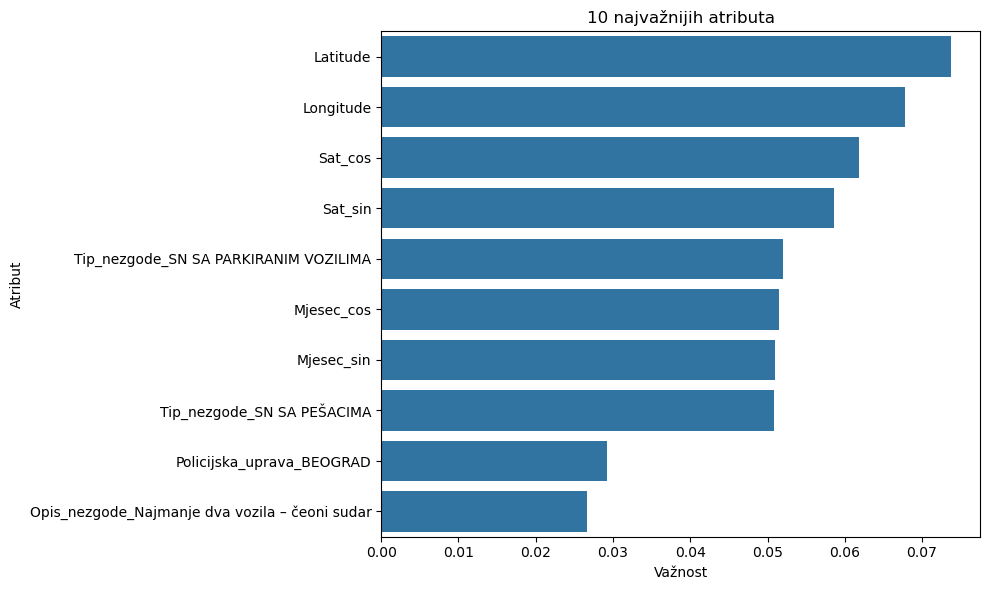

In [66]:
top10 = feature_importance.head(10)

plt.figure(figsize=(10, 6))
sns.barplot(data=top10, x="Važnost", y="Atribut")
plt.title("10 najvažnijih atributa")
plt.xlabel("Važnost")
plt.ylabel("Atribut")
plt.tight_layout()
plt.show()

In [67]:
grupe = {
    "Latitude": feature_importance.loc[feature_importance["Atribut"] == "Latitude", "Važnost"].sum(),
    "Longitude": feature_importance.loc[feature_importance["Atribut"] == "Longitude", "Važnost"].sum(),
    "Sat": feature_importance.loc[
        feature_importance["Atribut"].isin(["Sat_sin", "Sat_cos"]), "Važnost"
    ].sum(),
    "Mjesec": feature_importance.loc[
        feature_importance["Atribut"].isin(["Mjesec_sin", "Mjesec_cos"]), "Važnost"
    ].sum(),
    "Policijska_uprava": feature_importance.loc[
        feature_importance["Atribut"].str.startswith("Policijska_uprava_"), "Važnost"
    ].sum(),
    "Opstina": feature_importance.loc[
        feature_importance["Atribut"].str.startswith("Opstina_"), "Važnost"
    ].sum(),
    "Tip_nezgode": feature_importance.loc[
        feature_importance["Atribut"].str.startswith("Tip_nezgode_"), "Važnost"
    ].sum(),
    "Opis_nezgode": feature_importance.loc[
        feature_importance["Atribut"].str.startswith("Opis_nezgode_"), "Važnost"
    ].sum(),
    "Dan_u_sedmici": feature_importance.loc[
        feature_importance["Atribut"].str.startswith("Dan_u_sedmici_"), "Važnost"
    ].sum(),
}

grupe_df = (
    pd.DataFrame(grupe.items(), columns=["Originalni atribut", "Ukupna važnost"])
    .sort_values("Ukupna važnost", ascending=False)
)

grupe_df


,Originalni atribut,Ukupna važnost
7,Opis_nezgode,0.214914
6,Tip_nezgode,0.153123
2,Sat,0.120346
5,Opstina,0.114204
3,Mjesec,0.102488
4,Policijska_uprava,0.089515
0,Latitude,0.073804
1,Longitude,0.067842
8,Dan_u_sedmici,0.063763


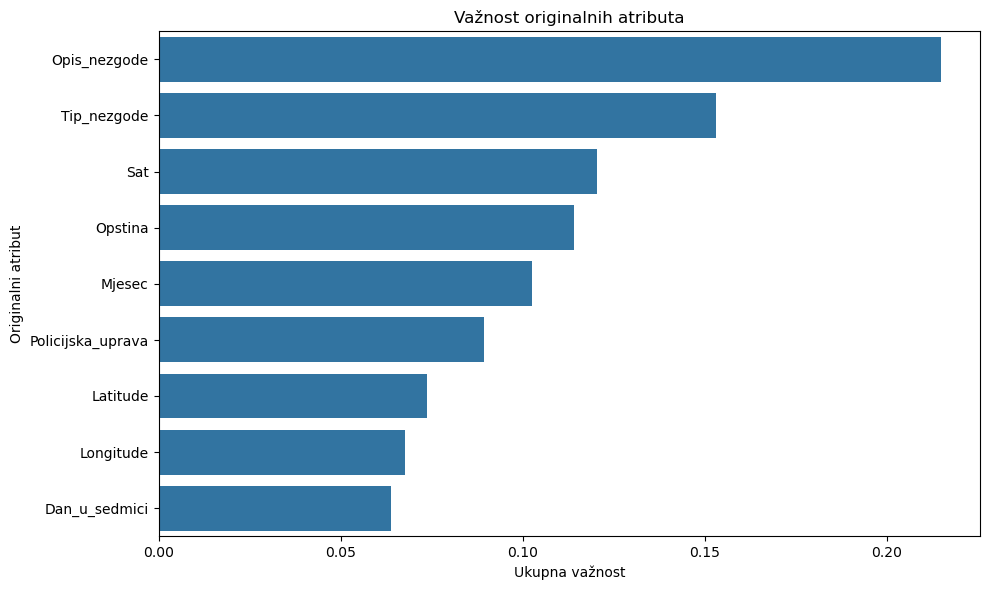

In [68]:
plt.figure(figsize=(10, 6))
sns.barplot(data=grupe_df, x="Ukupna važnost", y="Originalni atribut")
plt.title("Važnost originalnih atributa")
plt.xlabel("Ukupna važnost")
plt.ylabel("Originalni atribut")
plt.tight_layout()
plt.show()

## FAZA 12 — Unakrsna validacija (cross-validation)


In [69]:
preprocesor = ColumnTransformer(transformers=[
    ("num", "passthrough", numericke_kolone),
    ("cat", OneHotEncoder(handle_unknown="ignore"), kategorijske_kolone)
])

pipeline_rf_cv = ImbPipeline(steps=[
    ("smote", SMOTENC(categorical_features=indeksi_kategorijskih, random_state=42)),
    ("preprocess", preprocesor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        criterion="entropy",
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        class_weight="balanced_subsample"
    ))
])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Pratimo i f1_weighted (opšta mjera) i recall specifično za "Sa poginulim" (najbitnija mjera za ovaj rad)
scorer_recall_poginuli = make_scorer(
    lambda y_true, y_pred: recall_score(y_true, y_pred, labels=["Sa poginulim"], average=None, zero_division=0)[0]
)

cv_rezultati = cross_validate(
    pipeline_rf_cv, X_train, y_train,
    cv=skf,
    scoring={"f1_weighted": "f1_weighted", "recall_poginuli": scorer_recall_poginuli},
    n_jobs=-1
)

print("F1-weighted po foldu:          ", np.round(cv_rezultati["test_f1_weighted"], 4))
print(f"F1-weighted prosjek:            {cv_rezultati['test_f1_weighted'].mean():.4f}  (std: {cv_rezultati['test_f1_weighted'].std():.4f})")
print()
print("Recall 'Sa poginulim' po foldu:", np.round(cv_rezultati["test_recall_poginuli"], 4))
print(f"Recall 'Sa poginulim' prosjek:   {cv_rezultati['test_recall_poginuli'].mean():.4f}  (std: {cv_rezultati['test_recall_poginuli'].std():.4f})")



F1-weighted po foldu:           [0.7373 0.7358 0.7359 0.7313 0.7301]
F1-weighted prosjek:            0.7341  (std: 0.0028)

Recall 'Sa poginulim' po foldu: [0.0676 0.0667 0.0811 0.0946 0.0676]
Recall 'Sa poginulim' prosjek:   0.0755  (std: 0.0110)


## DODATAK — CatBoost sa nativnom podrškom za kategorijske atribute

In [70]:
X_train_cb = X_train_smote.copy()
X_test_cb = X_test.copy()

for kol in kategorijske_kolone:
    X_train_cb[kol] = X_train_cb[kol].astype(str)
    X_test_cb[kol] = X_test_cb[kol].astype(str)

catboost_model = CatBoostClassifier(
    iterations=300,
    depth=6,
    random_state=42,
    auto_class_weights="Balanced",
    verbose=False
)

catboost_model.fit(X_train_cb, y_train_smote, cat_features=kategorijske_kolone)
y_pred_cb = catboost_model.predict(X_test_cb)

accuracy_cb = accuracy_score(y_test, y_pred_cb)
f1_cb = f1_score(y_test, y_pred_cb, average="weighted")

print(f"Tačnost (CatBoost): {accuracy_cb:.4f}")
print(classification_report(y_test, y_pred_cb, zero_division=0))

Tačnost (CatBoost): 0.7375
                precision    recall  f1-score   support

 Sa mat.stetom       0.80      0.78      0.79      3964
  Sa poginulim       0.10      0.13      0.11        92
Sa povredjenim       0.67      0.70      0.68      2627

      accuracy                           0.74      6683
     macro avg       0.52      0.54      0.53      6683
  weighted avg       0.74      0.74      0.74      6683



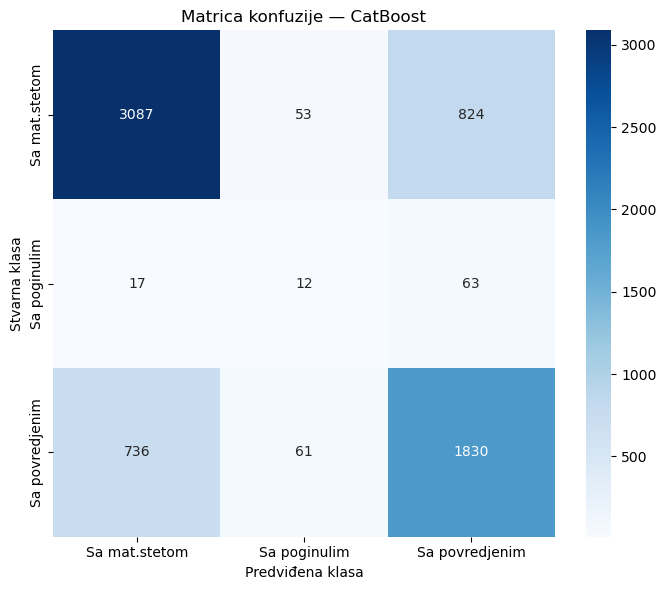

In [71]:
cm_cb = confusion_matrix(y_test, y_pred_cb)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_cb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=catboost_model.classes_,
    yticklabels=catboost_model.classes_
)

plt.title("Matrica konfuzije — CatBoost")
plt.xlabel("Predviđena klasa")
plt.ylabel("Stvarna klasa")
plt.tight_layout()
plt.show()

## FAZA 13 — Poređenje rezultata

In [49]:
rezultati_finalno = pd.DataFrame({
    "Model": ["Logistička regresija", "Decision Tree", "Random Forest", "CatBoost"],
    "Accuracy": [accuracy_lr, accuracy_dt, accuracy_rf, accuracy_cb],
    "Weighted F1-score": [f1_lr, f1_dt, f1_rf, f1_cb],
    "Recall (Sa poginulim)": [
        recall_score(y_test, y_pred_lr, labels=["Sa poginulim"], average=None)[0],
        recall_score(y_test, y_pred_dt, labels=["Sa poginulim"], average=None)[0],
        recall_score(y_test, y_pred_rf, labels=["Sa poginulim"], average=None)[0],
        recall_score(y_test, y_pred_cb, labels=["Sa poginulim"], average=None)[0],
    ]
})

print(rezultati_finalno)

                  Model  Accuracy  Weighted F1-score  Recall (Sa poginulim)
0  Logistička regresija  0.642077           0.686855               0.423913
1         Decision Tree  0.667215           0.691667               0.195652
2         Random Forest  0.726171           0.731734               0.108696
3              CatBoost  0.737543           0.739991               0.130435


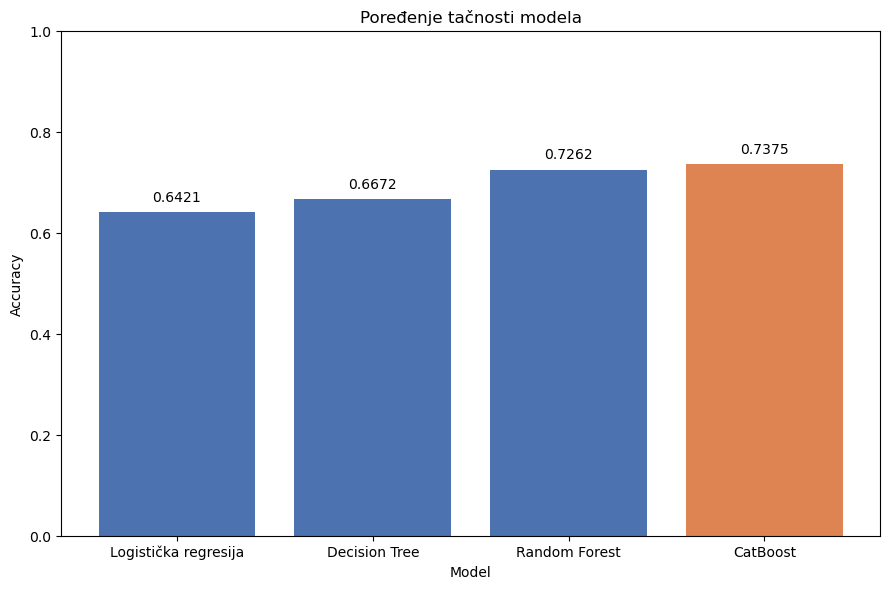

In [50]:
# Graficko poredjenje tacnosti sva 4 modela
plt.figure(figsize=(9, 6))
boje = ["#4C72B0", "#4C72B0", "#4C72B0", "#DD8452"]
bars = plt.bar(rezultati_finalno["Model"], rezultati_finalno["Accuracy"], color=boje)
plt.ylim(0, 1.0)
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.title("Poređenje tačnosti modela")
for bar, val in zip(bars, rezultati_finalno["Accuracy"]):
    plt.text(bar.get_x() + bar.get_width()/2, val + 0.02, f"{val:.4f}", ha="center", fontsize=10)
plt.tight_layout()
plt.show()